## Step 1: Data Ingestion & Workload Proxy Definition

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# 1. Load cleaned dataset from processed directory
df = pd.read_csv('../data/processed/customer_support_tickets_cleaned.csv')
print(f"Cleaned Dataset Loaded Successfully: {df.shape[0]:,} rows, {df.shape[1]} columns")

# 2. Operational Workload Proxy
df['is_unresolved'] = df['Ticket Status'].isin(['Open', 'Pending Customer Response'])
df.head(2)

Cleaned Dataset Loaded Successfully: 8,469 rows, 17 columns


,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating,is_unresolved
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN,True
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN,True


#### What I learn from this session
It Loads the cleaned dataset produced by Member 1 from data/processed/ and verifies the record count. It flags operational workload using is_unresolved (Open and Pending Customer Response) because the dataset lacks an explicit escalation column.

## Step 2: Problem Statement 3 — Ticket Type Workload & Hotspots

In [24]:
# Problem 3: Workload and Hotspots by Category
ticket_hotspots = (
    df.groupby('Ticket Type', dropna=False)
    .agg(
        total_tickets=('Ticket ID', 'nunique'),
        unresolved_count=('is_unresolved', 'sum'),
        mean_csat=('Customer Satisfaction Rating', 'mean'),
        csat_sample_size=('Customer Satisfaction Rating', 'count')
    )
    .reset_index()
)
ticket_hotspots['volume_share_pct'] = (ticket_hotspots['total_tickets'] / len(df) * 100).round(2)
ticket_hotspots['unresolved_rate_pct'] = (ticket_hotspots['unresolved_count'] / ticket_hotspots['total_tickets'] * 100).round(2)
ticket_hotspots['mean_csat'] = ticket_hotspots['mean_csat'].round(2)
ticket_hotspots = ticket_hotspots.sort_values(by='total_tickets', ascending=False)

print("=== PROBLEM 3: TICKET TYPE WORKLOAD HOTSPOTS ===")
display(ticket_hotspots)

=== PROBLEM 3: TICKET TYPE WORKLOAD HOTSPOTS ===


,Ticket Type,total_tickets,unresolved_count,mean_csat,csat_sample_size,volume_share_pct,unresolved_rate_pct
3,Refund request,1752,1156,2.93,596,20.69,65.98
4,Technical issue,1747,1167,2.96,580,20.63,66.80
1,Cancellation request,1695,1179,3.03,516,20.01,69.56
2,Product inquiry,1641,1108,3.02,533,19.38,67.52
0,Billing inquiry,1634,1090,3.03,544,19.29,66.71


#### What I learn from this session
It Groups tickets by Ticket Type to evaluate category volume, backlog proportions, and average customer satisfaction. This identifies whether specific ticket types (e.g., Refund or Technical issues) concentrate disproportionate operational pressure.

## Step 3:Problem 5 — Priority Breakdown vs. Operational Outcomes

In [25]:
# Problem 5: Priority Workload & Outcome Analysis
priority_summary = (
    df.groupby('Ticket Priority', dropna=False)
    .agg(
        total_tickets=('Ticket ID', 'nunique'),
        unresolved_count=('is_unresolved', 'sum'),
        mean_csat=('Customer Satisfaction Rating', 'mean'),
        csat_sample_size=('Customer Satisfaction Rating', 'count')
    )
    .reset_index()
)
priority_summary['volume_share_pct'] = (priority_summary['total_tickets'] / len(df) * 100).round(2)
priority_summary['unresolved_rate_pct'] = (priority_summary['unresolved_count'] / priority_summary['total_tickets'] * 100).round(2)
priority_summary['mean_csat'] = priority_summary['mean_csat'].round(2)
priority_summary = priority_summary.sort_values(by='total_tickets', ascending=False)

print("=== PROBLEM 5: PRIORITY BREAKDOWN ===")
display(priority_summary)

=== PROBLEM 5: PRIORITY BREAKDOWN ===


,Ticket Priority,total_tickets,unresolved_count,mean_csat,csat_sample_size,volume_share_pct,unresolved_rate_pct
3,Medium,2192,1498,2.98,694,25.88,68.34
0,Critical,2129,1403,2.96,726,25.14,65.90
1,High,2085,1380,2.98,705,24.62,66.19
2,Low,2063,1419,3.05,644,24.36,68.78


#### What I learn from this session
It Compares ticket priority levels against unresolved rates and average satisfaction ratings. It reveals whether Critical tickets receive prioritized operational closure or mirror low-priority backlog rates.

## Step 4: Problem Statement 6 — Channel Mix & Status Cross-Tabulation

In [26]:
# Problem 6: Channel Mix and Status Distribution
channel_status_distribution = pd.crosstab(
    df['Ticket Channel'],
    df['Ticket Status'],
    normalize='index'
).mul(100).round(2)

channel_type_crosstab = pd.crosstab(
    df['Ticket Channel'],
    df['Ticket Type'],
    margins=True,
    margins_name="Total"
)

print("=== PROBLEM 6: STATUS COMPOSITION BY CHANNEL (%) ===")
display(channel_status_distribution)

print("\n=== PROBLEM 6: CHANNEL VS TICKET TYPE VOLUME ===")
display(channel_type_crosstab)

=== PROBLEM 6: STATUS COMPOSITION BY CHANNEL (%) ===


Ticket Status,Closed,Open,Pending Customer Response
Ticket Channel,,,
Chat,32.51,33.04,34.44
Email,33.60,32.71,33.69
Phone,32.41,34.52,33.07
Social media,32.25,32.86,34.89



=== PROBLEM 6: CHANNEL VS TICKET TYPE VOLUME ===


Ticket Type,Billing inquiry,Cancellation request,Product inquiry,Refund request,Technical issue,Total
Ticket Channel,,,,,,
Chat,398,408,388,426,453,2073
Email,405,448,427,455,408,2143
Phone,434,426,424,427,421,2132
Social media,397,413,402,444,465,2121
Total,1634,1695,1641,1752,1747,8469


#### What I learn from this session
It Constructs cross-tabulations between support channels and ticket resolution statuses, as well as channel volume across categories. This confirms whether specific channels experience higher resolution rates or handle distinct ticket mixes.

## Step 5: Visualizations & Governance Audit

C:\Users\sktan\AppData\Local\Temp\ipykernel_16128\2738098921.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ticket_hotspots, x='Ticket Type', y='total_tickets', ax=ax1, palette='Blues_r')


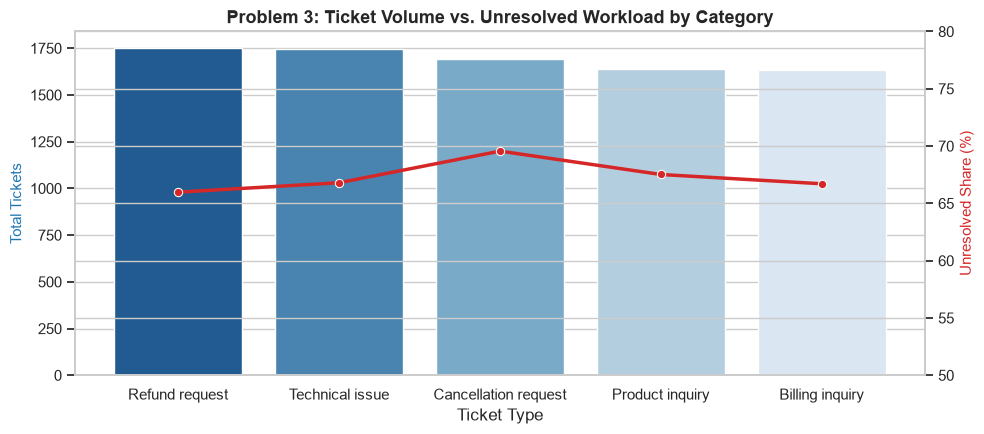

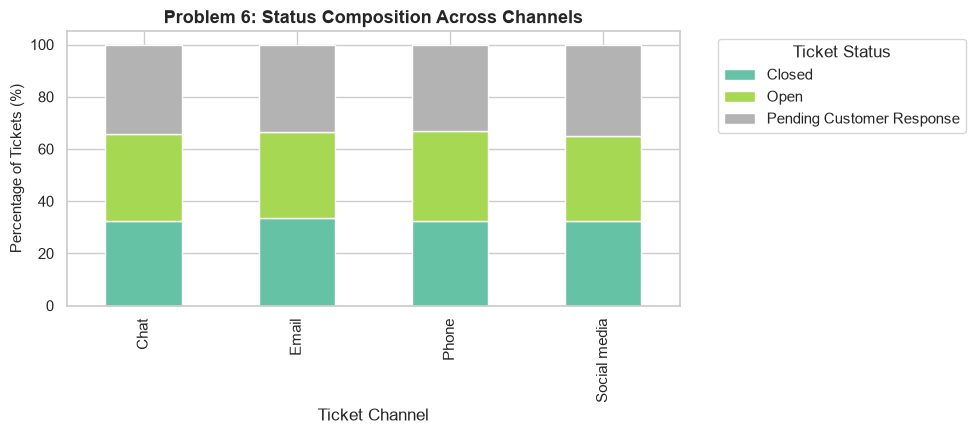


=== OFFICIAL DATA GOVERNANCE AUDIT ===
- Dataset contains no explicit 'Escalation' flag; calculations reflect operational backlog pressure.
- Dataset contains no 'Queue' or 'Department' field; queue routing cannot be directly audited.
- CSAT scores exist exclusively for closed tickets (n=2,769); missing CSAT count is 5,700 (~67.3%).


In [27]:
# Visualization 1: Dual-axis Bar + Line Chart (Problem 3)
fig, ax1 = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=ticket_hotspots, x='Ticket Type', y='total_tickets', ax=ax1, palette='Blues_r')
ax1.set_ylabel('Total Tickets', color='#1f77b4', fontsize=11)
ax1.set_title('Problem 3: Ticket Volume vs. Unresolved Workload by Category', fontsize=13, weight='bold')

ax2 = ax1.twinx()
sns.lineplot(data=ticket_hotspots, x='Ticket Type', y='unresolved_rate_pct', ax=ax2, color='#d62728', marker='o', linewidth=2.5)
ax2.set_ylabel('Unresolved Share (%)', color='#d62728', fontsize=11)
ax2.set_ylim(50, 80)
plt.tight_layout()
plt.show()

# Visualization 2: Stacked Status Chart (Problem 6)
channel_status_distribution.plot(kind='bar', stacked=True, figsize=(10, 4.5), colormap='Set2')
plt.title('Problem 6: Status Composition Across Channels', fontsize=13, weight='bold')
plt.ylabel('Percentage of Tickets (%)', fontsize=11)
plt.legend(title='Ticket Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Data Governance & Limitations Audit
print("\n=== OFFICIAL DATA GOVERNANCE AUDIT ===")
limitations = [
    "Dataset contains no explicit 'Escalation' flag; calculations reflect operational backlog pressure.",
    "Dataset contains no 'Queue' or 'Department' field; queue routing cannot be directly audited.",
    "CSAT scores exist exclusively for closed tickets (n=2,769); missing CSAT count is 5,700 (~67.3%)."
]
for item in limitations:
    print(f"- {item}")

#### What I learn from this session
It Renders a dual-axis chart comparing category volume to unresolved rates alongside a stacked bar chart of channel status distributions. It concludes by printing data governance limitations to guide final evaluation.